In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine

wine_load = load_wine()
wine = pd.DataFrame(wine_load.data, columns=wine_load.feature_names)
wine["Class"] = wine_load.target
wine["Class"] = wine["Class"].map({0 :'class_0', 1:'class_1', 2:'class_2'})

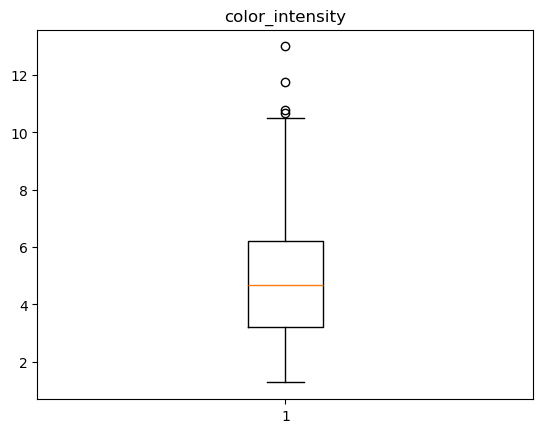

In [2]:
import matplotlib.pyplot as plt
plt.boxplot(wine['color_intensity'], whis=1.5)
plt.title('color_intensity')
plt.show()

In [3]:
def outliers_iqr(dt, col):
    quartile_1, quartile_3 = np.percentile(dt[col], [25, 75])
    iqr = quartile_3 - quartile_1
    lower_whis = quartile_1 - (iqr * 1.5)
    upper_whis = quartile_3 + (iqr * 1.5)
    outliers = dt[(dt[col] > upper_whis) | (dt[col] < lower_whis)]
    return outliers[[col]]

outliers = outliers_iqr(wine, 'color_intensity')
outliers

,color_intensity
151,10.80
158,13.00
159,11.75
166,10.68


In [4]:
drop_outliers = wine.drop(index=outliers.index)

print('Original :', wine.shape) # 이상치 제거 전의 shape
print('Drop outliers', drop_outliers.shape)  # 이상치 제거 후 shape

Original : (178, 14)
Drop outliers (174, 14)


In [5]:
wine.loc[outliers.index, 'color_intensity'] = np.nan

wine['color_intensity']
wine['color_intensity'].fillna(wine['color_intensity'].mean())
wine.loc[outliers.index, 'color_intensity']

151   NaN
158   NaN
159   NaN
166   NaN
Name: color_intensity, dtype: float64